# Result images — one figure per file

Reads the saved outputs of `robusta_chicory_nested_loso.ipynb` (and, for the comparison images, the earlier
notebooks) and writes one single-panel PNG per result to `final_regression/images/`. No retraining.

In [1]:
import os
import json, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

BASE = Path(os.environ.get("COFFEE_DATA", "../.."))
RES  = BASE / "final_regression"
IMG  = RES / "images"
IMG.mkdir(exist_ok=True, parents=True)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
S_COLOR  = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
S_MARKER = {1: "o", 2: "s", 3: "^"}
HIGHLIGHT, OTHER = "#2a78d6", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 180, "font.size": 11,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9.5,
})

PRED  = pd.read_csv(RES / "heldout_predictions_selected.csv")
OUTER = pd.read_csv(RES / "outer_folds_all_methods.csv")
SUMM  = pd.read_csv(RES / "method_summary.csv").set_index("model")
TUNE  = pd.read_csv(RES / "inner_tuning_log.csv")
INFO  = json.loads((RES / "summary.json").read_text())
SEL   = INFO["selected"]["method"]
FR    = OUTER[OUTER.model == SEL].set_index("held_out")
MEAN  = float(SUMM.loc[SEL, "mean_rmsep"])

def save(fig, name):
    fig.tight_layout()
    fig.savefig(IMG / name, bbox_inches="tight")
    plt.show()

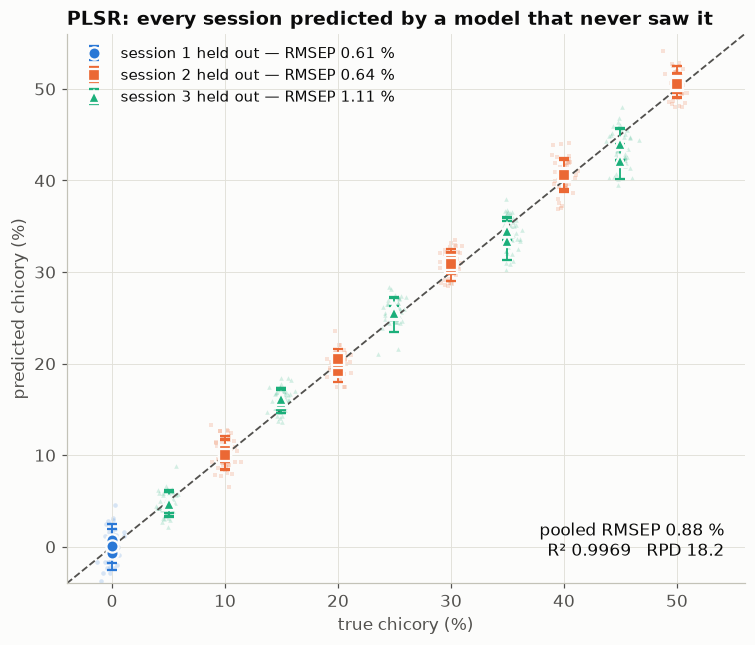

In [2]:
# 01 -- held-out predictions against the truth
pl = PRED.groupby(["fold", "group", "y"], as_index=False).agg(p=("p", "mean"), sd=("p", "std"))
lim = [-4, 56]
fig, ax = plt.subplots(figsize=(7, 6))
for s in (1, 2, 3):
    u, q = PRED[PRED.fold == s], pl[pl.fold == s]
    ax.scatter(u.y + np.random.default_rng(s).normal(0, .5, len(u)), u.p, s=9, alpha=.18,
               color=S_COLOR[s], marker=S_MARKER[s], lw=0)
    ax.errorbar(q.y, q.p, yerr=q.sd, fmt=S_MARKER[s], ms=8, color=S_COLOR[s], mec=SURFACE, mew=1.5,
                ecolor=S_COLOR[s], elinewidth=1.2, capsize=3, zorder=4,
                label=f"session {s} held out — RMSEP {FR.loc[s, 'rmsep_plate']:.2f} %")
ax.plot(lim, lim, ls="--", color=INK2, lw=1.2, zorder=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("true chicory (%)"); ax.set_ylabel("predicted chicory (%)")
lo = INFO["loso"]
ax.text(.97, .04, f"pooled RMSEP {lo['pooled_rmsep']:.2f} %\nR² {lo['pooled_r2']:.4f}   RPD {lo['rpd']:.1f}",
        transform=ax.transAxes, ha="right", va="bottom", color=INK)
ax.legend(loc="upper left")
ax.set_title(f"{SEL}: every session predicted by a model that never saw it", loc="left")
save(fig, "01_heldout_pred_vs_true.png")

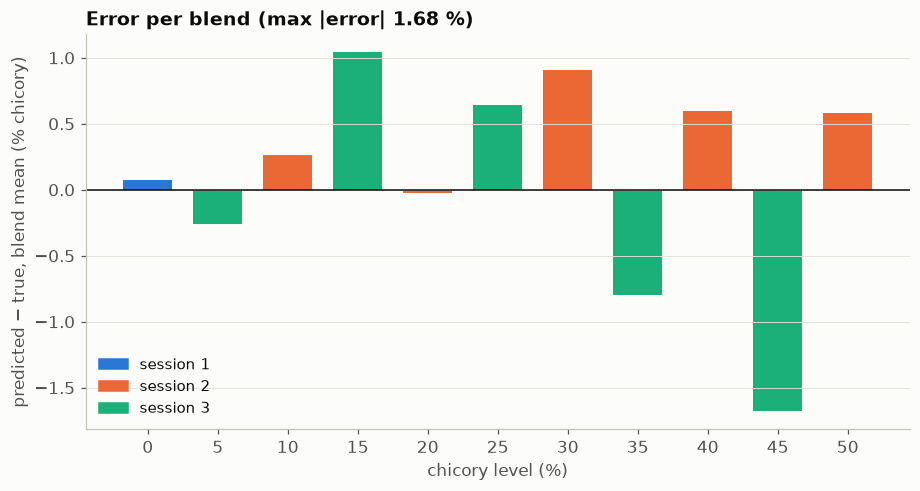

In [3]:
# 02 -- error of each blend
smp = PRED.groupby(["fold", "label", "y"], as_index=False)["p"].mean().sort_values("y")
smp["err"] = smp.p - smp.y
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.bar(np.arange(len(smp)), smp.err, width=.7, color=[S_COLOR[s] for s in smp.fold])
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(np.arange(len(smp)), [f"{v:.0f}" for v in smp.y])
ax.set_xlabel("chicory level (%)"); ax.set_ylabel("predicted − true, blend mean (% chicory)")
ax.legend(handles=[Patch(color=S_COLOR[s], label=f"session {s}") for s in (1, 2, 3)], loc="lower left")
ax.grid(axis="x", visible=False)
ax.set_title(f"Error per blend (max |error| {smp.err.abs().max():.2f} %)", loc="left")
save(fig, "02_error_per_blend.png")

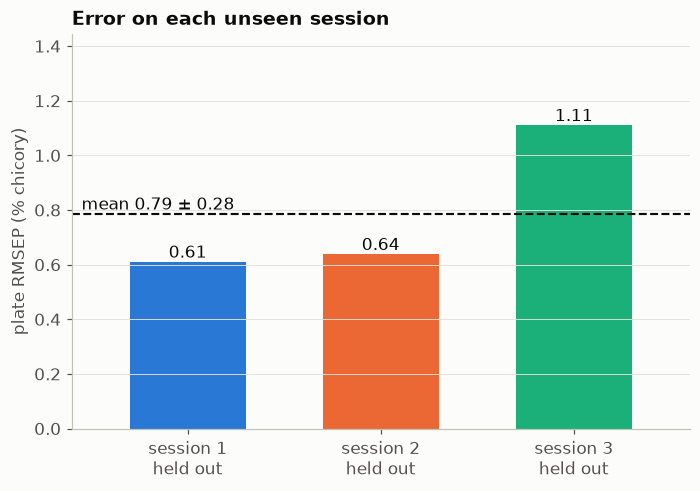

In [4]:
# 03 -- error on each held-out session, and their mean
vals = [FR.loc[s, "rmsep_plate"] for s in (1, 2, 3)]
fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.bar([1, 2, 3], vals, width=.6, color=[S_COLOR[s] for s in (1, 2, 3)])
for s, v in zip((1, 2, 3), vals):
    ax.text(s, v, f"{v:.2f}", ha="center", va="bottom", color=INK)
ax.axhline(MEAN, color=INK, ls="--", lw=1.4)
ax.text(.45, MEAN, f"mean {MEAN:.2f} ± {SUMM.loc[SEL, 'sd_rmsep']:.2f}", va="bottom", color=INK)
ax.set_xlim(.4, 3.6); ax.set_ylim(0, max(vals) * 1.3)
ax.set_xticks([1, 2, 3], [f"session {s}\nheld out" for s in (1, 2, 3)])
ax.set_ylabel("plate RMSEP (% chicory)"); ax.grid(axis="x", visible=False)
ax.set_title("Error on each unseen session", loc="left")
save(fig, "03_rmsep_per_session.png")

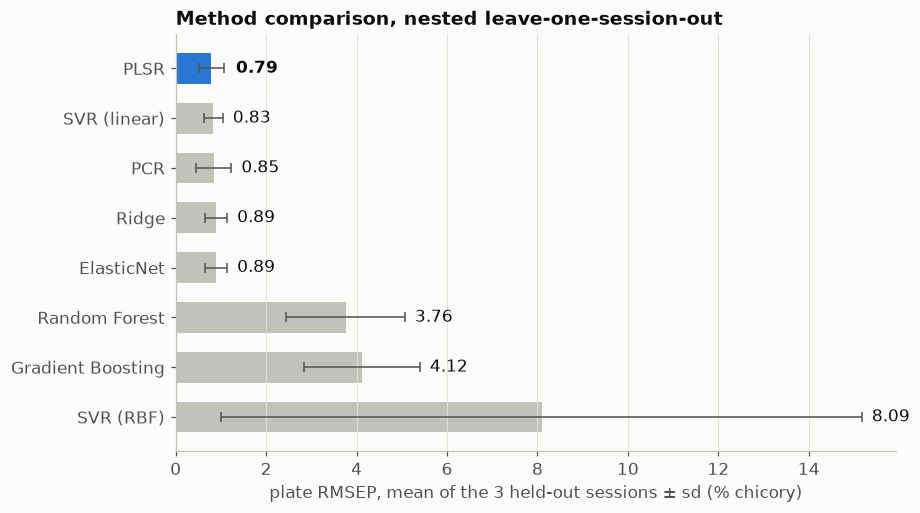

In [5]:
# 04 -- all methods, trained the same way
order = SUMM.sort_values("mean_rmsep").index.tolist()
v, e = SUMM.loc[order, "mean_rmsep"].to_numpy(), SUMM.loc[order, "sd_rmsep"].to_numpy()
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(np.arange(len(order)), v, height=.62, color=[HIGHLIGHT if m == SEL else OTHER for m in order],
        xerr=e, error_kw=dict(ecolor=INK2, elinewidth=1, capsize=3))
for i, (val, err) in enumerate(zip(v, e)):
    ax.text(val + err, i, f"  {val:.2f}", va="center", color=INK, fontweight="bold" if order[i] == SEL else "normal")
ax.set_yticks(np.arange(len(order)), order); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("plate RMSEP, mean of the 3 held-out sessions ± sd (% chicory)")
ax.set_title("Method comparison, nested leave-one-session-out", loc="left")
save(fig, "04_method_comparison.png")

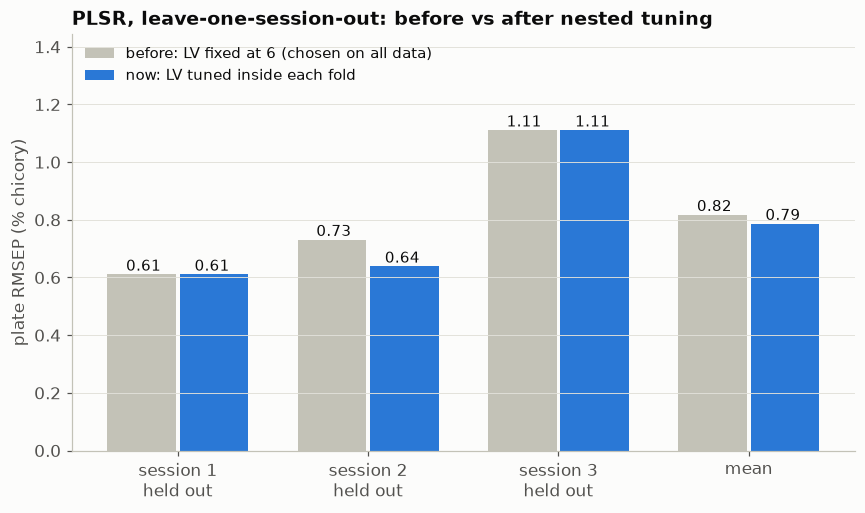

In [6]:
# 05 -- old vs new, like for like: leave-one-session-out with 6 LV fixed vs nested (tuned inside each fold)
old_path = BASE / "session_results" / "loso_by_session.csv"
if old_path.exists():
    old = pd.read_csv(old_path)
    old = old[old.model == "PLSR 6 LV"].set_index("held_out").rmsep_plate
    new = FR.rmsep_plate
    cats = ["session 1\nheld out", "session 2\nheld out", "session 3\nheld out", "mean"]
    a = [old[1], old[2], old[3], old.mean()]
    b = [new[1], new[2], new[3], new.mean()]
    x, w = np.arange(4), .36
    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.bar(x - w / 2 - .01, a, w, color=OTHER, label="before: LV fixed at 6 (chosen on all data)")
    ax.bar(x + w / 2 + .01, b, w, color=HIGHLIGHT, label="now: LV tuned inside each fold")
    for xi, (p, q) in enumerate(zip(a, b)):
        ax.text(xi - w / 2, p, f"{p:.2f}", ha="center", va="bottom", color=INK, fontsize=10)
        ax.text(xi + w / 2, q, f"{q:.2f}", ha="center", va="bottom", color=INK, fontsize=10)
    ax.set_xticks(x, cats); ax.set_ylim(0, max(a + b) * 1.3)
    ax.set_ylabel("plate RMSEP (% chicory)"); ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left")
    ax.set_title("PLSR, leave-one-session-out: before vs after nested tuning", loc="left")
    save(fig, "05_before_vs_after_nesting.png")
else:
    print("session_results/loso_by_session.csv not found -- image 05 skipped")

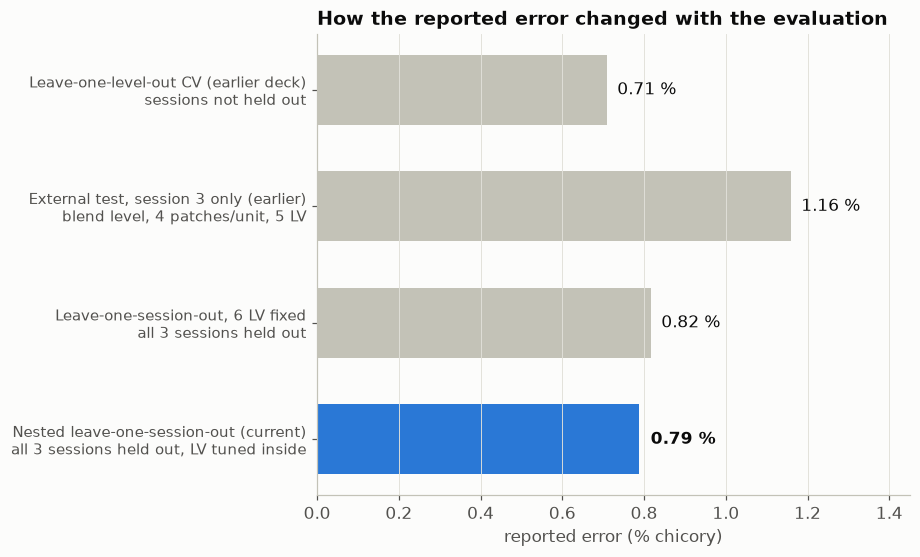

In [7]:
# 06 -- every error figure reported for the selected model so far, and what each one tested
rows = []
p = BASE / "results.json"
if p.exists():
    rows.append(("Leave-one-level-out CV (earlier deck)\nsessions not held out", json.loads(p.read_text())["final_model"]["rmsecv_plate"], False))
p = BASE / "final_results" / "summary.json"
if p.exists():
    rows.append(("External test, session 3 only (earlier)\nblend level, 4 patches/unit, 5 LV", json.loads(p.read_text())["external_validation"]["rmsep"], False))
p = BASE / "session_results" / "loso_by_session.csv"
if p.exists():
    o = pd.read_csv(p)
    rows.append(("Leave-one-session-out, 6 LV fixed\nall 3 sessions held out", o[o.model == "PLSR 6 LV"].rmsep_plate.mean(), False))
rows.append(("Nested leave-one-session-out (current)\nall 3 sessions held out, LV tuned inside", MEAN, True))

fig, ax = plt.subplots(figsize=(8.5, 0.95 * len(rows) + 1.4))
y = np.arange(len(rows))
ax.barh(y, [r[1] for r in rows], height=.6, color=[HIGHLIGHT if r[2] else OTHER for r in rows])
for i, r in enumerate(rows):
    ax.text(r[1], i, f"  {r[1]:.2f} %", va="center", color=INK, fontweight="bold" if r[2] else "normal")
ax.set_yticks(y, [r[0] for r in rows], fontsize=9.5); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(r[1] for r in rows) * 1.25)
ax.set_xlabel("reported error (% chicory)")
ax.set_title("How the reported error changed with the evaluation", loc="left")
save(fig, "06_evaluation_history.png")

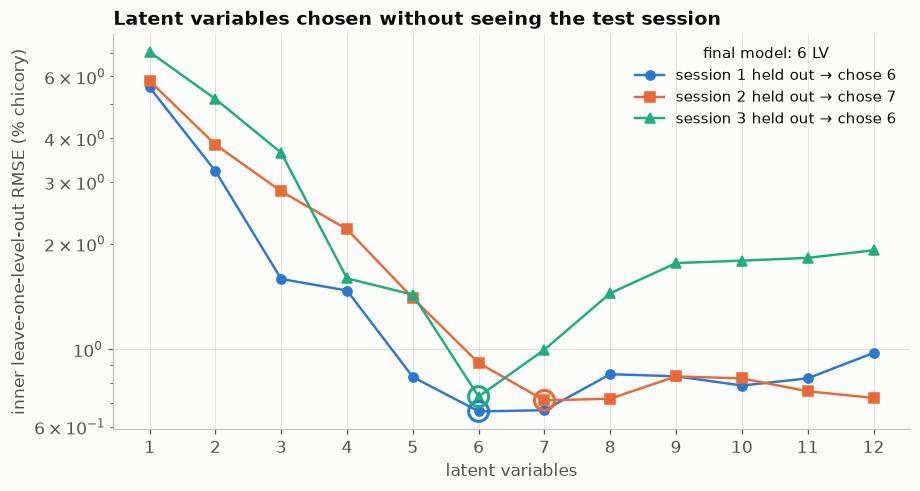

In [8]:
# 07 -- choosing the number of latent variables inside each fold
t = TUNE[TUNE.model == SEL]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for s in (1, 2, 3):
    q = t[t.outer == s].reset_index(drop=True)
    ax.plot(q.param, q["mean"], color=S_COLOR[s], marker=S_MARKER[s], ms=6, lw=1.6,
            label=f"session {s} held out → chose {int(FR.loc[s, 'param'])}")
    c = q[q.chosen].iloc[0]
    ax.scatter(c.param, c["mean"], s=170, facecolor="none", edgecolor=S_COLOR[s], lw=2, zorder=5)
ax.set_yscale("log")
ax.set_xticks(sorted(t.param.unique()))
ax.set_xlabel("latent variables"); ax.set_ylabel("inner leave-one-level-out RMSE (% chicory)")
ax.legend(loc="upper right", title=f"final model: {INFO['selected']['final_param']} LV", title_fontsize=9.5)
ax.set_title("Latent variables chosen without seeing the test session", loc="left")
save(fig, "07_latent_variable_choice.png")

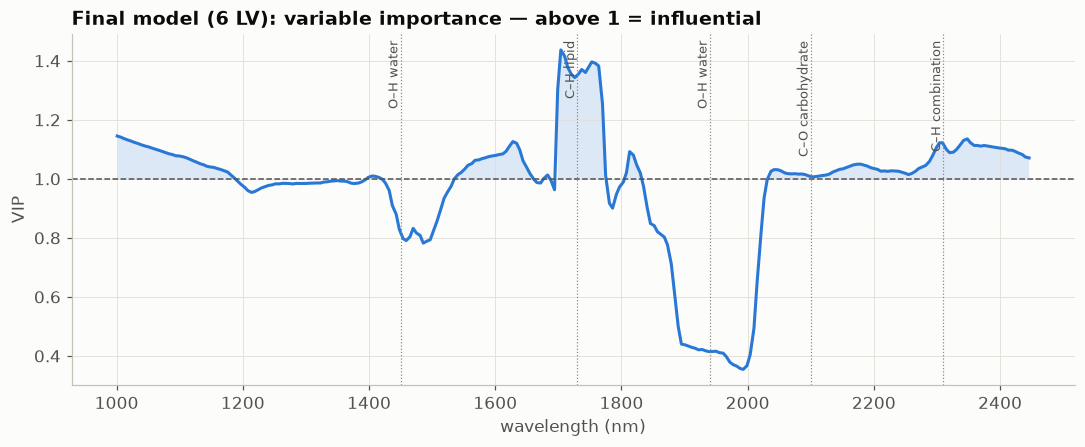

In [9]:
# 08 -- which wavelengths the final model relies on
with open(RES / "robusta_chicory_model.pkl", "rb") as fh:
    B = pickle.load(fh)
m, WL = B["model"], np.asarray(B["wavelengths"])
if hasattr(m, "x_weights_"):
    W_, T_, Q_ = m.x_weights_, m.x_scores_, m.y_loadings_.ravel()
    ss = (Q_ ** 2) * (T_ ** 2).sum(0)
    vip = np.sqrt(WL.size * ((W_ ** 2 / (W_ ** 2).sum(0)) @ ss) / ss.sum())
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.fill_between(WL, 1, vip, where=vip > 1, color=HIGHLIGHT, alpha=.15, lw=0)
    ax.plot(WL, vip, color=HIGHLIGHT, lw=2)
    ax.axhline(1, color=INK2, ls="--", lw=1)
    for nm, lab in [(1450, "O–H water"), (1730, "C–H lipid"), (1940, "O–H water"),
                    (2100, "C–O carbohydrate"), (2310, "C–H combination")]:
        ax.axvline(nm, color=MUTED, lw=.8, ls=":")
        ax.text(nm, .98, lab, transform=ax.get_xaxis_transform(), rotation=90, va="top", ha="right",
                fontsize=8.5, color=INK2)
    ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("VIP")
    ax.set_title(f"Final model ({B['param']} LV): variable importance — above 1 = influential", loc="left")
    save(fig, "08_variable_importance.png")